# Arch Prime: where does a liquidation actually lose money?
**A deterministic stress model built on Arch's published mechanics (v0.1)**

**What this is:** an independent, illustrative model. It is *not* Arch's internal model,
and it uses no Arch private data.

**Sources (public):** Arch docs, *How it works* (risk weights, health, leverage ceiling,
liquidation order, insurance vault, socialized loss) and *Risk overview*
(strategy-first risk, closeout price vs NAV, shortfall).

**Inputs are split into two groups, on purpose:**
- **DOCUMENTED**: numbers/rules Arch publishes (cited in the comments).
- **ASSUMED**: numbers Arch does *not* publish. These are placeholders to be replaced or
  challenged. Every conclusion that depends on them is labelled as such.

**Key modelling assumption (from the docs' wording):** the strategy receipt counts as collateral
only "if that receipt is a bankable mint", at that bank's asset weight. This model assumes it is,
at an unpublished weight. If it were not, any leveraged account would fail the health check
immediately (BTC alone, weighted at 0.65-0.75, cannot cover 2x-5x debt), so leveraged accounts
in the docs' form imply bankable receipts. Confirm with the team.

**Sources re-checked against the live pages on 24 Oct 2026:** docs *How it works*,
*Risk overview*, *Glossary*.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams.update({"figure.dpi": 130, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---------------- DOCUMENTED (arch.network/docs/prime/02-how-it-works) ----------------
W_BTC_INIT, W_BTC_MAINT = 0.65, 0.75   # aBTC asset weights (docs example; liability weight 1.0)
LIAB_W = 1.0                           # archUSD liability weight in the docs example
MAX_LEVERAGE = 5.0                     # stated ceiling
# Liquidatable when maintenance health <= 0, where
#   health = sum(amount*price*asset_weight) - sum(amount*price*liability_weight)
# Closeout order: deployed strategy = rank 1, Bitcoin = rank 99 (sold last, only if needed).
# Shortfall -> insurance vault first, then socialized to depositors (lower asset share value).

# ---------------- ASSUMED (NOT published by Arch) ----------------
W_REC_INIT = 0.90    # asset weight of the strategy receipt at initial check  (ASSUMPTION)
W_REC_MAINT = 0.95   # asset weight of the strategy receipt at maintenance    (ASSUMPTION)
E0 = 100_000.0       # starting equity, USD of BTC collateral (illustrative)

## 1. Account mechanics (as documented)
A borrow is always deployed into the strategy, so **debt = deployed position = λ × equity**
(λ = leverage). That reproduces both documented facts:
- a strategy impairment of **1/λ** exhausts equity (5× → 20%), and
- a 100% BTC drawdown with the deployed leg intact still leaves the debt covered.

In [2]:
def max_leverage_from_weights(w_btc_init=W_BTC_INIT, w_rec_init=W_REC_INIT, liab_w=LIAB_W):
    """Highest leverage that passes the *initial* check, if weights were the only constraint.
    assets = w_btc*E + w_rec*lam*E ; liabilities = liab_w*lam*E  ->  lam <= w_btc / (liab_w - w_rec)"""
    return w_btc_init / (liab_w - w_rec_init)

def weight_needed_for_5x(w_btc_init=W_BTC_INIT, liab_w=LIAB_W, lev=MAX_LEVERAGE):
    return liab_w - w_btc_init / lev

print(f"Receipt init weight needed for a 5.0x ceiling to pass the init check: "
      f">= {weight_needed_for_5x():.3f}")
print(f"With the assumed receipt init weight ({W_REC_INIT}), weights alone would allow "
      f"{max_leverage_from_weights():.1f}x, so the documented 5.0x must come from the "
      f"strategy-drawdown rule, not the weights.")

Receipt init weight needed for a 5.0x ceiling to pass the init check: >= 0.870
With the assumed receipt init weight (0.9), weights alone would allow 6.5x, so the documented 5.0x must come from the strategy-drawdown rule, not the weights.


In [3]:
def maint_health(btc_val, rec_val, debt, w_rec_m=W_REC_MAINT):
    return W_BTC_MAINT * btc_val + w_rec_m * rec_val - LIAB_W * debt

def strat_impairment_at_breach(btc_move, lev, w_rec_m=W_REC_MAINT):
    """Strategy impairment x* at which maintenance health hits 0, given a BTC move.
    Returns <0 if the account is already liquidatable from the BTC move alone."""
    return 1 - (lev - W_BTC_MAINT * (1 + btc_move)) / (lev * w_rec_m)

def strat_impairment_equity_zero(btc_move, lev):
    """Strategy impairment at which equity is exhausted *at NAV* (before any execution cost)."""
    return (1 + btc_move) / lev

## 2. Closeout engine (documented order, assumed costs)
Order: sell the deployed strategy first (rank 1), then Bitcoin (rank 99) only as needed.
Costs are the unknowns: **`sale_disc`** = strategy sold below NAV (docs: sale realises market
price, not NAV, and they diverge most in a cascade); **`sweep_disc`** = BTC swept at a
discount to market (docs: "sweeps Bitcoin collateral at a discount to market").

In [4]:
def closeout(lev, btc_move, strat_move, sale_disc, sweep_disc,
             gap_btc=0.0, gap_strat=0.0, w_rec_m=W_REC_MAINT, E=E0):
    """Returns a dict for one account.
    btc_move / strat_move: change at the moment of BREACH DETECTION (e.g. -0.4, -0.1).
    gap_*: extra adverse move between detection and execution (latency/venue stress)."""
    debt = lev * E
    btc_b = E * (1 + btc_move)
    rec_b = lev * E * (1 + strat_move)
    h = maint_health(btc_b, rec_b, debt, w_rec_m)
    out = dict(lev=lev, btc_move=btc_move, strat_move=strat_move,
               health_at_breach=h, liquidatable=h <= 0)
    if h > 0:
        out.update(nav_equity=btc_b + rec_b - debt, recovered=np.nan, lender_loss=0.0,
                   user_residual=btc_b + rec_b - debt, loss_pct_debt=0.0, btc_sold_share=0.0)
        return out
    # execution happens at post-gap prices
    btc_x = btc_b * (1 + gap_btc)
    rec_x = rec_b * (1 + gap_strat)
    rec_proceeds = rec_x * (1 - sale_disc)                      # rank 1
    remaining = max(0.0, debt - rec_proceeds)
    btc_needed = remaining / (1 - sweep_disc)                   # market value of BTC to sell
    btc_sold = min(btc_x, btc_needed)                           # rank 99, only if needed
    btc_proceeds = btc_sold * (1 - sweep_disc)
    recovered = rec_proceeds + btc_proceeds
    lender_loss = max(0.0, debt - recovered)
    user_residual = max(0.0, recovered + (btc_x - btc_sold) - debt)
    out.update(nav_equity=btc_b + rec_b - debt, recovered=recovered, lender_loss=lender_loss,
               user_residual=user_residual, loss_pct_debt=lender_loss / debt,
               btc_sold_share=(btc_sold / btc_x) if btc_x > 0 else np.nan)
    return out

## 3. Chart 1: how much cushion sits between "liquidated" and "underwater"?
The gap between the two lines is the room the closeout has to absorb sale discount,
sweep discount and any price gap *before lenders lose a dollar*. (Uses the assumed receipt weight.)

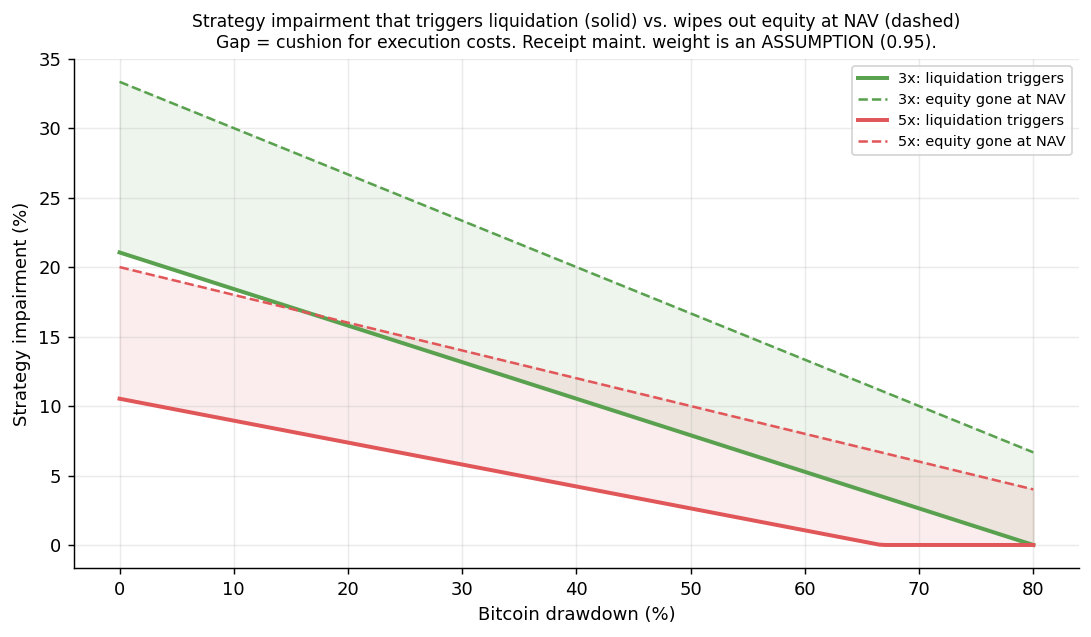


At zero BTC move, assumed receipt weight 0.95:
  2x: trigger at 34.2% impairment | equity gone at 50.0% | cushion = 15.8% of deployed = $31,579 on $100,000 equity
  3x: trigger at 21.1% impairment | equity gone at 33.3% | cushion = 12.3% of deployed = $36,842 on $100,000 equity
  4x: trigger at 14.5% impairment | equity gone at 25.0% | cushion = 10.5% of deployed = $42,105 on $100,000 equity
  5x: trigger at 10.5% impairment | equity gone at 20.0% | cushion = 9.5% of deployed = $47,368 on $100,000 equity


In [5]:
b = np.linspace(0, -0.8, 161)
fig, ax = plt.subplots(figsize=(8.5, 5))
colors = {2: "#4C78A8", 3: "#59A14F", 4: "#F28E2B", 5: "#E15759"}
for lev in (3, 5):
    xs = np.clip(strat_impairment_at_breach(b, lev), 0, None)
    xe = np.clip(strat_impairment_equity_zero(b, lev), 0, None)
    ax.plot(-b * 100, xs * 100, color=colors[lev], lw=2.2, label=f"{lev}x: liquidation triggers")
    ax.plot(-b * 100, xe * 100, color=colors[lev], lw=1.4, ls="--", label=f"{lev}x: equity gone at NAV")
    ax.fill_between(-b * 100, xs * 100, xe * 100, color=colors[lev], alpha=0.10)
ax.set_xlabel("Bitcoin drawdown (%)")
ax.set_ylabel("Strategy impairment (%)")
ax.set_title("Strategy impairment that triggers liquidation (solid) vs. wipes out equity at NAV (dashed)\n"
             "Gap = cushion for execution costs. Receipt maint. weight is an ASSUMPTION (0.95).", fontsize=9.5)
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig("figures/chart1_trigger_vs_insolvency.png"); plt.show()

print("\nAt zero BTC move, assumed receipt weight 0.95:")
for lev in (2, 3, 4, 5):
    xs = strat_impairment_at_breach(0, lev); xe = strat_impairment_equity_zero(0, lev)
    cushion_usd = (xe - xs) * lev * E0
    print(f"  {lev}x: trigger at {xs:5.1%} impairment | equity gone at {xe:5.1%} | "
          f"cushion = {xe - xs:4.1%} of deployed = ${cushion_usd:,.0f} on ${E0:,.0f} equity")

## 4. Chart 2: lender shortfall heatmap at 5.0×
Rows: how far below NAV the strategy sells. Columns: strategy impairment at breach.
Left: BTC unchanged. Right: BTC −50% (so the BTC backstop is thinner).
Grey = account not liquidatable at that point. Sweep discount fixed at 3% (ASSUMPTION).

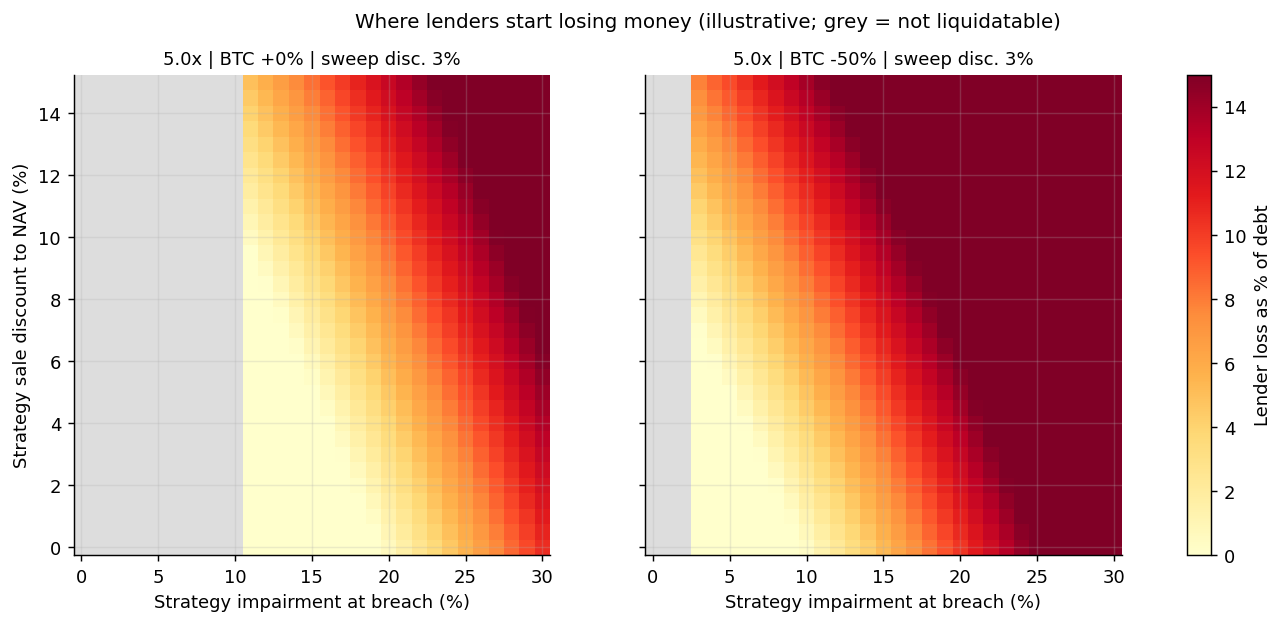

In [6]:
imp = np.arange(0.0, 0.31, 0.01)
disc = np.arange(0.0, 0.151, 0.005)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, btc_move in zip(axes, (0.0, -0.50)):
    grid = np.full((len(disc), len(imp)), np.nan)
    for i, d in enumerate(disc):
        for j, x in enumerate(imp):
            r = closeout(5.0, btc_move, -x, sale_disc=d, sweep_disc=0.03)
            if r["liquidatable"]:
                grid[i, j] = r["loss_pct_debt"] * 100
    cmap = plt.get_cmap("YlOrRd").copy(); cmap.set_bad("#DDDDDD")
    im = ax.pcolormesh(imp * 100, disc * 100, np.ma.masked_invalid(grid), cmap=cmap, vmin=0, vmax=15, shading="nearest")
    ax.set_title(f"5.0x | BTC {btc_move:+.0%} | sweep disc. 3%", fontsize=10)
    ax.set_xlabel("Strategy impairment at breach (%)")
axes[0].set_ylabel("Strategy sale discount to NAV (%)")
fig.colorbar(im, ax=axes, label="Lender loss as % of debt")
fig.suptitle("Where lenders start losing money (illustrative; grey = not liquidatable)", fontsize=11)
plt.savefig("figures/chart2_shortfall_heatmap.png", bbox_inches="tight"); plt.show()

## 5. Scenario table
Scenario values are **illustrative**, chosen to isolate one driver at a time.
None of them is an Arch forecast or an Arch parameter.

In [7]:
scenarios = [
    # name,                        lev, btc,  strat, sale, sweep, gapB, gapS
    ("A. Calm market",              5.0,  0.00,  0.00, 0.01, 0.01, 0.0,  0.0),
    ("B. BTC crash, strategy fine", 5.0, -0.50,  0.00, 0.01, 0.01, 0.0,  0.0),
    ("C. Strategy -12%, BTC flat",  5.0,  0.00, -0.12, 0.03, 0.02, 0.0,  0.0),
    ("D. Strategy -20%, BTC flat",  5.0,  0.00, -0.20, 0.03, 0.02, 0.0,  0.0),
    ("E. Cascade (BTC -50%, strat -12%, wide spreads)",
                                    5.0, -0.50, -0.12, 0.08, 0.05, -0.05, -0.03),
    ("F. Same as E at 3.0x",        3.0, -0.50, -0.12, 0.08, 0.05, -0.05, -0.03),
]
rows = []
for name, lev, bm, sm, sd, sw, gb, gs in scenarios:
    r = closeout(lev, bm, sm, sd, sw, gb, gs)
    rows.append({"Scenario": name, "Lev": lev, "BTC move": f"{bm:+.0%}", "Strategy move": f"{sm:+.0%}",
                 "Liquidatable": r["liquidatable"],
                 "Equity at NAV ($)": round(r["nav_equity"]),
                 "Lender loss ($)": round(r["lender_loss"]),
                 "Loss % of debt": f"{r['loss_pct_debt']:.1%}",
                 "User residual ($)": round(r["user_residual"]),
                 "BTC sold": ("n/a" if not r["liquidatable"] else f"{r['btc_sold_share']:.0%}")})
table = pd.DataFrame(rows)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
print(table.to_string(index=False))
table.to_csv("data/scenario_table.csv", index=False)

                                       Scenario  Lev BTC move Strategy move  Liquidatable  Equity at NAV ($)  Lender loss ($) Loss % of debt  User residual ($) BTC sold
                                 A. Calm market  5.0      +0%           +0%         False             100000                0           0.0%             100000      n/a
                    B. BTC crash, strategy fine  5.0     -50%           +0%         False              50000                0           0.0%              50000      n/a
                     C. Strategy -12%, BTC flat  5.0      +0%          -12%          True              40000                0           0.0%              25306      75%
                     D. Strategy -20%, BTC flat  5.0      +0%          -20%          True                  0            14000           2.8%                  0     100%
E. Cascade (BTC -50%, strat -12%, wide spreads)  5.0     -50%          -12%          True             -10000            62219          12.4%               

**How to read the table (important):**
- Scenarios are *jump states*: the market arrives at that point without a liquidation having
  fired on the way. On a smooth path, a 5.0x account would be closed out near **10.5%** strategy
  impairment (assumed weights), with roughly **$47k** of equity still left to pay for execution.
- So lender losses (D, E) require one of three things: the trigger fires **late** (stale or wrong
  NAV mark, oracle stall, venue outage), execution costs **exceed the cushion**, or both.
  Arch's own risk page lists NAV marks and venue failures as principal risks for this reason.
- Scenario C shows the other side: the *user* pays execution costs first (equity falls from
  $40k at NAV to about $25k after closeout) and lenders are untouched.

## 6. Sensitivity: how much do the *assumed* numbers matter?
Because Arch does not publish the receipt weight, show how the trigger point moves with it.

In [8]:
print("Strategy impairment that triggers liquidation at 5.0x, BTC flat:")
for w in (0.87, 0.90, 0.93, 0.95, 0.98, 1.00):
    xs = strat_impairment_at_breach(0, 5.0, w_rec_m=w)
    print(f"  receipt maint. weight {w:.2f}  ->  trigger at {xs:5.1%} impairment "
          f"(equity gone at 20.0%)")
print("\nBTC drawdown alone (strategy intact) that triggers liquidation at 5.0x:")
for w in (0.90, 0.93, 0.95, 0.98):
    # solve strat_impairment_at_breach(b)=0
    b_star = (5.0 * (1 - w) / W_BTC_MAINT) - 1
    print(f"  receipt maint. weight {w:.2f}  ->  BTC {b_star:+.0%}")

Strategy impairment that triggers liquidation at 5.0x, BTC flat:
  receipt maint. weight 0.87  ->  trigger at  2.3% impairment (equity gone at 20.0%)
  receipt maint. weight 0.90  ->  trigger at  5.6% impairment (equity gone at 20.0%)
  receipt maint. weight 0.93  ->  trigger at  8.6% impairment (equity gone at 20.0%)
  receipt maint. weight 0.95  ->  trigger at 10.5% impairment (equity gone at 20.0%)
  receipt maint. weight 0.98  ->  trigger at 13.3% impairment (equity gone at 20.0%)
  receipt maint. weight 1.00  ->  trigger at 15.0% impairment (equity gone at 20.0%)

BTC drawdown alone (strategy intact) that triggers liquidation at 5.0x:
  receipt maint. weight 0.90  ->  BTC -33%
  receipt maint. weight 0.93  ->  BTC -53%
  receipt maint. weight 0.95  ->  BTC -67%
  receipt maint. weight 0.98  ->  BTC -87%


## What this does and does not show
**Shown (given the stated assumptions):** at high leverage the thing that reaches equity first is
the *strategy leg*, not BTC; liquidation triggers well before equity hits zero; and the cushion
between those two points is what absorbs execution costs. Lenders only lose money when
*execution cost + gap* exceeds that cushion, and BTC (sold last) is the second line.

**Not shown / not claimed:** real execution discounts, real recovery ratios, real time-to-close,
real receipt weights, insurance-vault size, or any Arch performance data. Those are exactly the
questions to put to the team.